<a href="https://colab.research.google.com/github/anishkumarcs24/BIS/blob/main/MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CUCKOO SEARCH SVM - SUPPLY CHAIN RISK MANAGEMENT

1. DATASET GENERATED SUCCESSFULLY
   Supplier_Reliability  Defect_Rate  Lead_Time  Flexibility  \
0                     7            9          1            6   
1                     4           14         21            6   
2                     8            1         22            4   
3                     5            1         21           10   
4                     7           14          6           10   

   Manufacturing_Capability Risk_Level  
0                         1     Medium  
1                         7       High  
2                         1     Medium  
3                         5     Medium  
4                        10        Low  

Risk Distribution:
Risk_Level
Medium    285
High      127
Low        88
Name: count, dtype: int64

2. DATA PREPROCESSING COMPLETED
Training records: 400
Testing records: 100

3. STARTING CUCKOO SEARCH OPTIMIZATION
Iteration 1/20 - Best F1 Score: 0.9187
Iteration 2/20 - Best F1 Score:

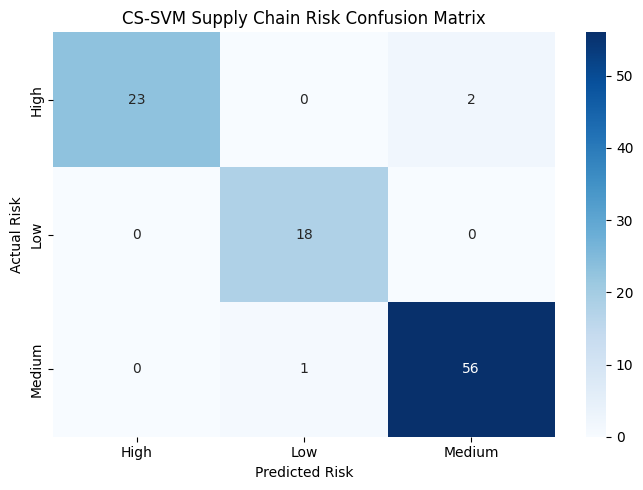

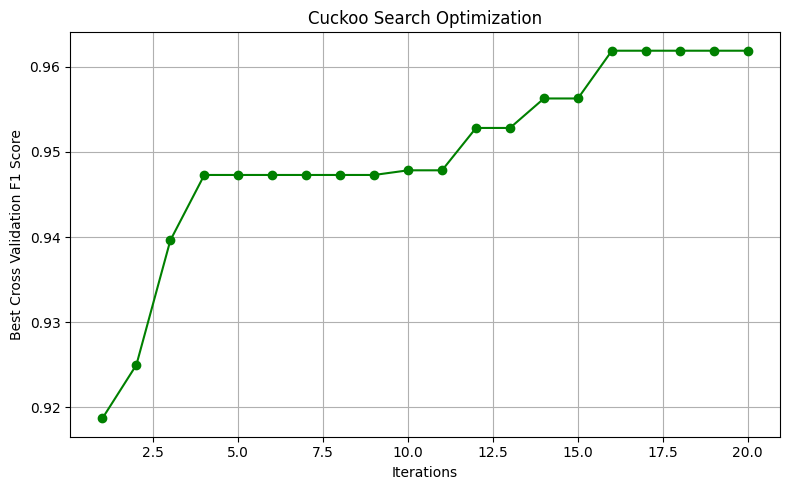

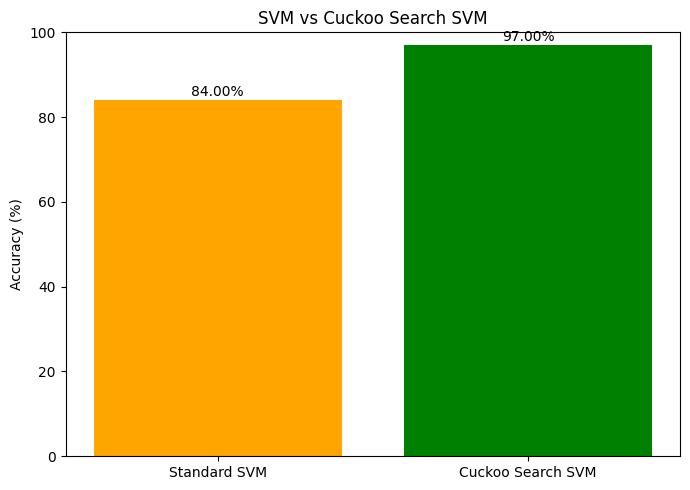


7. NEW SUPPLIER RISK PREDICTION
   Supplier_Reliability  Defect_Rate  Lead_Time  Flexibility  \
0                     3            8         15            2   

   Manufacturing_Capability  
0                         4  

Predicted Risk Level: Medium
ACTION: Monitor supplier performance.

8. RESULTS SAVED SUCCESSFULLY
File: CS_SVM_Prediction_Results.csv
File: supply_chain.csv

CS-SVM PROJECT EXECUTION COMPLETED


In [ ]:
%pip -q install numpy pandas scikit-learn matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, precision_score,
    recall_score, f1_score
)

np.random.seed(42)

print("=" * 60)
print("CUCKOO SEARCH SVM - SUPPLY CHAIN RISK MANAGEMENT")
print("=" * 60)


# 2. GENERATE SUPPLY CHAIN DATASET

n = 500

data = pd.DataFrame({
    "Supplier_Reliability": np.random.randint(1, 11, n),
    "Defect_Rate": np.random.randint(1, 16, n),
    "Lead_Time": np.random.randint(1, 31, n),
    "Flexibility": np.random.randint(1, 11, n),
    "Manufacturing_Capability": np.random.randint(1, 11, n)
})

# Calculate supply chain risk score

risk_score = (
    (10 - data["Supplier_Reliability"]) * 0.25 +
    data["Defect_Rate"] * 0.20 +
    data["Lead_Time"] * 0.20 +
    (10 - data["Flexibility"]) * 0.15 +
    (10 - data["Manufacturing_Capability"]) * 0.20
)

data["Risk_Level"] = pd.cut(
    risk_score,
    bins=[-np.inf, 5, 9, np.inf],
    labels=["Low", "Medium", "High"]
)

data.to_csv("supply_chain.csv", index=False)

print("\n1. DATASET GENERATED SUCCESSFULLY")
print(data.head())
print("\nRisk Distribution:")
print(data["Risk_Level"].value_counts())


# 3. DATA PREPROCESSING

X = data.drop("Risk_Level", axis=1)
y = data["Risk_Level"]

encoder = LabelEncoder()
y = encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n2. DATA PREPROCESSING COMPLETED")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


# 4. CREATE SVM MODEL

def create_model(C, gamma):

    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("svm", SVC(
            C=C,
            gamma=gamma,
            kernel="rbf",
            class_weight="balanced"
        ))
    ])


# 5. CUCKOO SEARCH LEVY FLIGHT

def levy_flight(size, beta=1.5):

    sigma = (
        math.gamma(1 + beta) *
        np.sin(np.pi * beta / 2) /
        (
            math.gamma((1 + beta) / 2) *
            beta *
            2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma, size)
    v = np.random.normal(0, 1, size)

    return u / (np.abs(v) ** (1 / beta) + 1e-10)


# 6. FITNESS FUNCTION

def fitness(position):

    C = 10 ** position[0]
    gamma = 10 ** position[1]

    model = create_model(C, gamma)

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    return scores.mean()


# 7. CUCKOO SEARCH OPTIMIZATION

def cuckoo_search(nests=10, iterations=20, pa=0.25):

    lower = np.array([-2.0, -4.0])
    upper = np.array([4.0, 2.0])

    population = np.random.uniform(
        lower, upper, (nests, 2)
    )

    scores = np.array([
        fitness(nest) for nest in population
    ])

    best_index = np.argmax(scores)

    best_nest = population[best_index].copy()
    best_score = scores[best_index]

    history = []

    for iteration in range(iterations):

        for i in range(nests):

            step = levy_flight(2)

            new_nest = population[i] + (
                0.01 * step *
                (population[i] - best_nest)
            )

            new_nest = np.clip(
                new_nest, lower, upper
            )

            new_score = fitness(new_nest)

            if new_score > scores[i]:

                population[i] = new_nest
                scores[i] = new_score

        # Abandon poor nests and generate new solutions

        abandoned = np.random.rand(nests) < pa

        for i in range(nests):

            if abandoned[i]:

                population[i] = np.random.uniform(
                    lower, upper
                )

                scores[i] = fitness(population[i])

        current_best = np.argmax(scores)

        if scores[current_best] > best_score:

            best_score = scores[current_best]
            best_nest = population[current_best].copy()

        history.append(best_score)

        print(
            f"Iteration {iteration + 1}/{iterations} "
            f"- Best F1 Score: {best_score:.4f}"
        )

    return best_nest, best_score, history


# 8. RUN CUCKOO SEARCH

print("\n3. STARTING CUCKOO SEARCH OPTIMIZATION")

best_parameters, best_fitness, history = cuckoo_search()

best_C = 10 ** best_parameters[0]
best_gamma = 10 ** best_parameters[1]

print("\nOPTIMAL PARAMETERS")
print("Best C:", best_C)
print("Best Gamma:", best_gamma)
print("Best CV F1 Score:", best_fitness)


# 9. TRAIN OPTIMIZED SVM MODEL

print("\n4. TRAINING OPTIMIZED SVM")

cs_svm = create_model(best_C, best_gamma)

cs_svm.fit(X_train, y_train)

print("Model training completed!")


# 10. TRAIN STANDARD SVM FOR COMPARISON

print("\n5. TRAINING STANDARD SVM")

standard_svm = create_model(1.0, "scale")

standard_svm.fit(X_train, y_train)


# 11. PREDICTION

y_pred = cs_svm.predict(X_test)

standard_pred = standard_svm.predict(X_test)


# 12. MODEL EVALUATION

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

standard_accuracy = accuracy_score(y_test, standard_pred)

print("\n6. CS-SVM PERFORMANCE")
print("=" * 40)
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")

print("\nSTANDARD SVM PERFORMANCE")
print(f"Accuracy: {standard_accuracy * 100:.2f}%")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))


# 13. CONFUSION MATRIX

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_))
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title("CS-SVM Supply Chain Risk Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.tight_layout()
plt.show()


# 14. CUCKOO SEARCH OPTIMIZATION GRAPH

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(history) + 1),
    history,
    marker="o",
    color="green"
)

plt.title("Cuckoo Search Optimization")
plt.xlabel("Iterations")
plt.ylabel("Best Cross Validation F1 Score")
plt.grid(True)
plt.tight_layout()
plt.show()


# 15. MODEL COMPARISON GRAPH

plt.figure(figsize=(7, 5))

models = ["Standard SVM", "Cuckoo Search SVM"]
accuracies = [
    standard_accuracy * 100,
    accuracy * 100
]

plt.bar(
    models,
    accuracies,
    color=["orange", "green"]
)

plt.ylabel("Accuracy (%)")
plt.title("SVM vs Cuckoo Search SVM")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()


# 16. PREDICT NEW SUPPLIER RISK

new_supplier = pd.DataFrame([{
    "Supplier_Reliability": 3,
    "Defect_Rate": 8,
    "Lead_Time": 15,
    "Flexibility": 2,
    "Manufacturing_Capability": 4
}])

prediction = cs_svm.predict(new_supplier)

predicted_risk = encoder.inverse_transform(prediction)[0]

print("\n7. NEW SUPPLIER RISK PREDICTION")
print("=" * 40)
print(new_supplier)
print("\nPredicted Risk Level:", predicted_risk)

if predicted_risk == "High":
    print("ACTION: Evaluate alternative suppliers.")
elif predicted_risk == "Medium":
    print("ACTION: Monitor supplier performance.")
else:
    print("ACTION: Continue regular supplier monitoring.")


# 17. SAVE RESULTS

results = X_test.copy()

results["Actual_Risk"] = encoder.inverse_transform(y_test)
results["Predicted_Risk"] = encoder.inverse_transform(y_pred)

results.to_csv("CS_SVM_Prediction_Results.csv", index=False)

print("\n8. RESULTS SAVED SUCCESSFULLY")
print("File: CS_SVM_Prediction_Results.csv")
print("File: supply_chain.csv")

print("\n" + "=" * 60)
print("CS-SVM PROJECT EXECUTION COMPLETED")
print("=" * 60)